# snow Tutorial 2 - Time and Frequency Grids

Every snow simulation lives on a discrete time grid and the frequency grid that the FFT associates with it. This notebook shows how to choose them.

First things first: imports and units.

In [1]:
import numpy as np
from numpy.fft import fftfreq, fftshift
import matplotlib.pyplot as plt

from scipy.constants import pi, c, epsilon_0
nm = 1e-9
um = 1e-6
mm = 1e-3
ps = 1e-12
fs = 1e-15
MHz = 1e6
GHz = 1e9
THz = 1e12
pJ = 1e-12
fJ = 1e-15
mW = 1e-3
uW = 1e-6

plt.rcParams.update({'font.size': 14})

## Bandwidth

Time and frequency are tied together by the Fourier transform, so we only need to choose one of the two grids. Usually what you know is the range of wavelengths the simulation must hold, so we start there. The band must contain **every frequency the nonlinear process can generate**: for SHG of a 2 µm pump, the pump and its second harmonic at 1 µm; for an OPO pumped at 1 µm, the signal and idler as well. Light generated outside the band is lost, or worse, aliased.

Here we take 0.8 µm to 4.5 µm, enough for a 2 µm pump, its second harmonic and a mid-infrared idler.

In [2]:
λ_1 = 800*nm
λ_2 = 4.5*um
f_max = c/λ_1
f_min = c/λ_2
BW = f_max - f_min
print('Bandwidth = %0.1f THz (%0.1f to %0.1f THz)' %(BW/THz, f_min/THz, f_max/THz))

Bandwidth = 308.1 THz (66.6 to 374.7 THz)


## Number of points

Next we choose the number of samples $N$, which is the same in both domains. The window sizes ($T$ in time, $\mathrm{BW}$ in frequency) and the resolutions ($\Delta t$, $\Delta f$) are related by the discrete Fourier transform:

$$
\Delta t\,\Delta f = \frac{1}{N}, \qquad T \times \mathrm{BW} = N,
$$

and also $\mathrm{BW} = N\Delta f$ and $T = N\Delta t$. So the bandwidth fixes the time step, $\Delta t = 1/\mathrm{BW}$, and $N$ then fixes the time window $T = N/\mathrm{BW}$ and the frequency resolution $\Delta f = 1/T$.

The only thing left to choose is where the time window starts. snow centres it on $t = 0$: the grid is $t_k = (k - N/2)\,\Delta t$, so $t = 0$ is the sample at index $N/2$.

In [3]:
N = 2**10   #a power of 2 makes the FFT fastest, but any N works

Δt = 1/BW   #time resolution
T = N*Δt    #time window
t = (np.arange(N) - N//2)*Δt   #time grid, centred on t = 0
f = fftfreq(N, Δt)             #frequency grid

print('N  = %d' %N)
print('Δt = %0.3f fs,   T  = %0.3f ps' %(Δt/fs, T/ps))
print('Δf = %0.1f GHz,  BW = %0.1f THz' %((f[1]-f[0])/GHz, BW/THz))

N  = 1024
Δt = 3.245 fs,   T  = 3.323 ps
Δf = 300.9 GHz,  BW = 308.1 THz


Build the time grid from the integer index, as above. `np.arange(-T/2, T/2, Δt)` looks equivalent, but with a floating-point step it can return $N+1$ points depending on rounding.

## Absolute frequency and wavelength

The frequency vector `f` is at baseband: it runs from $-\mathrm{BW}/2$ to $\mathrm{BW}/2$ around zero. The pulse envelope is defined relative to a reference frequency `f_ref`, so the physical frequency of each bin is `f + f_ref`. We put `f_ref` at the centre of the band.

In [4]:
f_ref = (f_max + f_min)/2  #reference frequency, supplied to the pulse functions
f_abs = f + f_ref          #absolute frequency of each bin
λ = c/f_abs                #wavelength of each bin
print('f_ref = %0.1f THz (λ = %0.3f um)' %(f_ref/THz, c/f_ref/um))
print('Absolute frequencies from %0.1f to %0.1f THz' %(f_abs.min()/THz, f_abs.max()/THz))

f_ref = 220.7 THz (λ = 1.358 um)
Absolute frequencies from 66.6 to 374.4 THz


`f_abs` must stay positive. With `f_ref` at the band centre this is automatic; if you move `f_ref` towards the low-frequency edge, snow warns when the grid reaches zero frequency.

## FFT order

`fftfreq` returns the frequencies in the order the FFT uses: zero first, then the positive frequencies, then the negative ones. All snow spectra (`pulse.A`, `pulse.f_abs`, `pulse.wl`, ...) are stored in this order. Use `fftshift` to put them in increasing order for plotting.

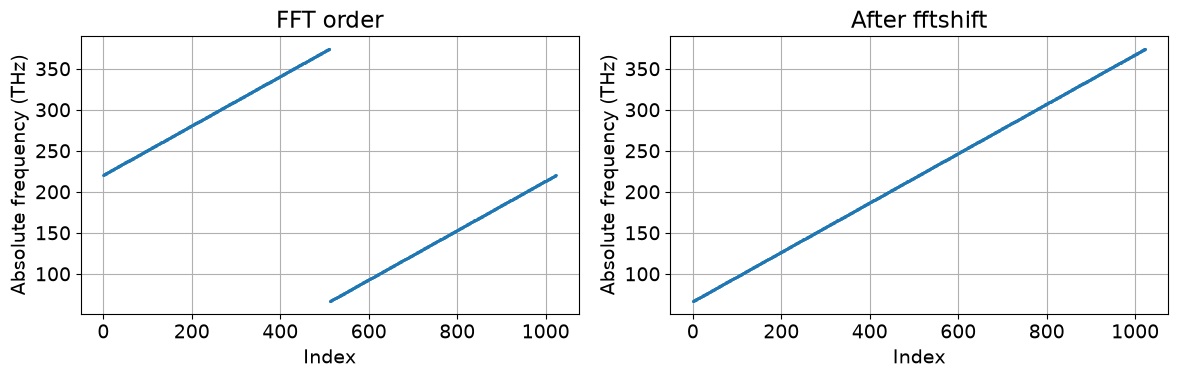

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), tight_layout=True)
ax1.plot(f_abs/THz, '.', ms=2)
ax1.set_title('FFT order')
ax1.set_xlabel('Index'); ax1.set_ylabel('Absolute frequency (THz)')
ax2.plot(fftshift(f_abs)/THz, '.', ms=2)
ax2.set_title('After fftshift')
ax2.set_xlabel('Index'); ax2.set_ylabel('Absolute frequency (THz)')
ax1.grid(True); ax2.grid(True)

## Wavelength resolution

The grid is uniform in frequency, so it is not uniform in wavelength. The wavelength spacing between bins is $\Delta\lambda = \lambda^2 \Delta f / c$: the resolution is coarser at long wavelengths. This matters when you look at narrow spectral features in the mid-infrared.

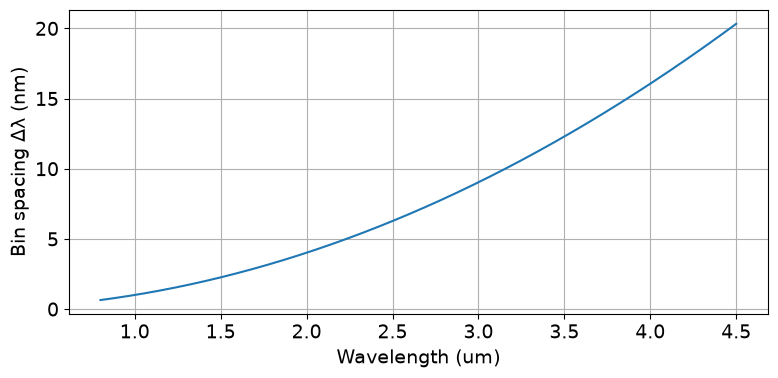

In [6]:
Δf = f[1] - f[0]
λs = fftshift(λ)
fig, ax = plt.subplots(figsize=(8, 4), tight_layout=True)
ax.plot(λs/um, λs**2*Δf/c/nm)
ax.set_xlabel('Wavelength (um)'); ax.set_ylabel('Bin spacing Δλ (nm)')
ax.grid(True)

## How large should N be?

The time window must hold everything that happens during the simulation, because the FFT grid is periodic: anything that leaves one edge of the window comes back in at the other.

- The window moves at a velocity `v_ref` that you choose (Tutorial 5). Pulses travelling at other group velocities drift across it. Over a length $L$, two pulses separate by $|\Delta\beta_1| L$, where $\Delta\beta_1$ is their group-velocity mismatch (Tutorial 4). The window must hold the pulse widths plus this walk-off.
- Pulses also broaden from dispersion, and parametric processes can generate long pulses.
- In frequency, $\Delta f = 1/T$ must resolve the narrowest spectral feature you care about.

For example, a 100 fs pump in a 4 mm waveguide with a GVM of 13 fs/mm to its second harmonic walks off by about 50 fs, so a window of a few ps (as here) is plenty. Doubling $N$ doubles $T$ at the same bandwidth, at roughly twice the cost.

In [7]:
L = 4*mm
GVM = 13*fs/mm
τ = 100*fs
print('Walk-off over %0.0f mm: %0.0f fs, pulse width %0.0f fs, window %0.2f ps' %(L/mm, GVM*L/fs, τ/fs, T/ps))

Walk-off over 4 mm: 52 fs, pulse width 100 fs, window 3.32 ps


## Summary

- Choose the bandwidth so it contains every frequency the process can generate.
- $\Delta t = 1/\mathrm{BW}$; $N$ sets the window $T = N\Delta t$.
- The grid is centred on $t=0$ and its frequencies are relative to `f_ref`.
- Spectra are in FFT order; `fftshift` sorts them.

You will pass `t` and `f_ref` to the pulse functions in the next tutorial. The `Pulse` object then computes its own `f`, `f_abs`, `wl`, ... from them.